**7장 - 앙상블 학습과 랜덤 포레스트**

**앙상블 방법**은 랜덤으로 선택된 수천 명의 사람에게 복잡한 질문을 하고 대답을 모은다고 했을때 이 대답들이 전문가의 답보다 더 낫다라는 **대중의 지혜**라는 개념을 예측기에 접목시킨 것.

**랜덤 포레스트**는 훈련 세트로부터 랜덤으로 각기 다른 거브셋을 만들어 일련의 결정 트리 분류기를 훈련시켜, 개별 트리의 예측을 모아 가장 많은 선택을 받는 클래스를 앙상블의 예측으로 삼는 것

# 설정


이 프로젝트를 실행하려면 파이썬 3.7이상이 필요함

In [27]:
import sys
assert sys.version_info >= (3, 7)

또한 사이킷런  1.0.1 이상이 필요함

In [28]:
from packaging import version
import sklearn
assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

기본 글꼴 크기 정의

In [29]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

plt.rcParams['font.family'] = 'Malgun Gothic'

이미지를 저장할 경로와 함수를 정의

In [30]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "ensemble_learning_and_random_forests"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

In [31]:
from sklearn import set_config

set_config(display="text")

# 투표 기반 분류기

정확도가 80%인 분류기 여러 개를 훈련시켰다고 가정함. 아마 로지스틱 회귀 분류기, SVM 분류기, 랜덤 포레스트 분류기, k-최근접 이웃 분류기 등을 가지고 있을 수 있음.

더 좋은 분류기를 만드는 매우 간단한 방법은 각 분류기의 예측으 집계하는 것. 가장 많은 표를 얻은 클래스가 앙상블의 예측이 됨. 이렇게 다수결 투표로 정해지는 분류기를 **직접 튜표** 분류기라고 함

이 다수결 분류기가 앙상블에 포함된 개별 분류기 중 가장 뛰어난 것보다도 정확도가 높은 경우가 많음. **약한 학습기**일지라도 앙상블에 있는 약한 삭습기가 충분하게 많고 다양하다면 앙상블은 **깡한 학습기**가 될 수 있음.

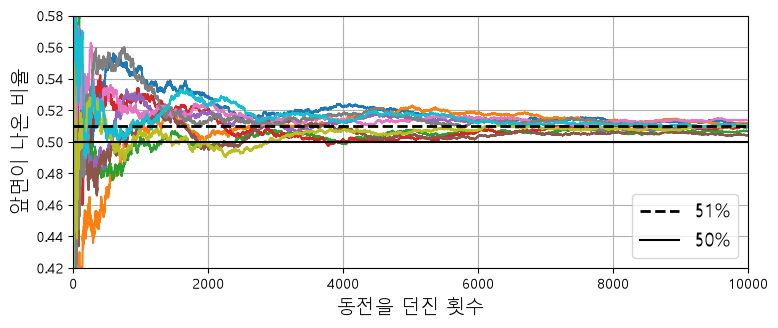

In [32]:
import matplotlib.pyplot as plt
import numpy as np

heads_proba = 0.51
np.random.seed(42)
coin_tosses = (np.random.rand(10000, 10) < heads_proba).astype(np.int32)
cumulative_heads = coin_tosses.cumsum(axis=0)
cumulative_heads_ratio = cumulative_heads / np.arange(1, 10001).reshape(-1, 1)

plt.figure(figsize=(8, 3.5))
plt.plot(cumulative_heads_ratio)
plt.plot([0, 10000], [0.51, 0.51], "k--", linewidth=2, label="51%")
plt.plot([0, 10000], [0.5, 0.5], "k-", label="50%")
plt.xlabel("동전을 던진 횟수")
plt.ylabel("앞면이 나온 비율")
plt.legend(loc="lower right")
plt.axis([0, 10000, 0.42, 0.58])
plt.grid()
save_fig("law_of_large_numbers_plot")
plt.show()

앞 뒤가 51:49비율로 나오는 동전이 있다고 가정함. **큰 수의 법칙**에 따라 동전을 던지면 던질 수록 앞면이 나오는 비율은 점점 더 앞면이 나올 확률이 됨.

sklearn은 VotingClassifier 클래스를 제공함.

In [33]:
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = make_moons(n_samples=500, noise=0.30, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

voting_clf = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression(random_state=42)),
        ('rf', RandomForestClassifier(random_state=42)),
        ('svc', SVC(random_state=42))
    ]
)
voting_clf.fit(X_train, y_train)

VotingClassifier(estimators=[('lr', LogisticRegression(random_state=42)),
                             ('rf', RandomForestClassifier(random_state=42)),
                             ('svc', SVC(random_state=42))])

In [34]:
for name, clf in voting_clf.named_estimators_.items():
    print(name, "=", clf.score(X_test, y_test))

lr = 0.864
rf = 0.896
svc = 0.896


In [35]:
voting_clf.predict(X_test[:1])

array([1])

In [36]:
[clf.predict(X_test[:1]) for clf in voting_clf.estimators_]

[array([1]), array([1]), array([0])]

In [37]:
voting_clf.score(X_test, y_test)

0.912

In [38]:
voting_clf.voting = "soft"
voting_clf.named_estimators["svc"].probability = True
voting_clf.fit(X_train, y_train)
voting_clf.score(X_test, y_test)

c:\Users\SSAFY\Desktop\my\study\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.92

# 배깅과 페이스팅

다양한 분류기르 ㄹ만든느 또다른 방법은 같은 알고리즘을 사용하고 훈련 ㅅ세트의 서브셋을 랜덤으로 구성하여 분류기를 각기 다르게 학습싯키는 것.

훈련세트에서 중복을 허용하여 샘플링하는 방식을 **배깅(bagging)**, 중복을 허용하지 않고 샘플링하는 방식을 **페이스팅(pasting)** 이라고 합니다.

모든 예측기가 훈련을 마치면 앙상블은 모든 예측기의 예측을 모아서 새로운 샘플에 대한 예측을 만듦. 집계 함수는 일반적으로 분류일 떄는 **통계적 최빈값(statistical mode)** 을, 회귀에 대해서는 평균을 계산함. 개별 예측기는 원본 훈련 세트로 훈련시킨 것보다 후러씬 크게 편향되어 있지만 집계 함수를 통과하면 편향과 분산이 모두 감소함. 일반저긍로 앙상블의 결과는 원본 데이터셋으로 하나ㅡ이 옟ㄱ기를 훈련시킬 떄와 비교해 편향은 비슷하지만 분산은 줄어듦.

예측기는 동시에 다른 CPU코어나 서버에서 병렬로 학습시킬 수 있음. 이와 유사하게 예측도 병렬로 수행할 수 있음. 이런 확장성 덕분에 배깅과 페이스티으이 인기가 높음.